# code_071 · Shift stress tests and external evidence

**Book:** section 14.5. A self-contained deployment-matched validation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_14_GUIDE.md), [run evidence](../CHAPTER_14_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_071).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1471;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1471


<a id="source"></a>
## Select on the source, then freeze the procedure

Source steel/site A: load uniform 10–60 kN and age uniform 0–30 years. Response=.2+.04*load+.1*age+Gaussian(.15), in a synthetic response unit. Train 500 independent members; select among a standardized Ridge alpha=1, fixed histogram boosting (100 iterations, seven leaves, early stopping disabled), and training-mean baseline using 150 development members and MSE. Only load and age enter the fit. Site/material metadata define challenge cohorts; material is constant in training and its change is unidentifiable from source observations. Fixed seeds, no final retuning and no claim of mechanistic transfer.


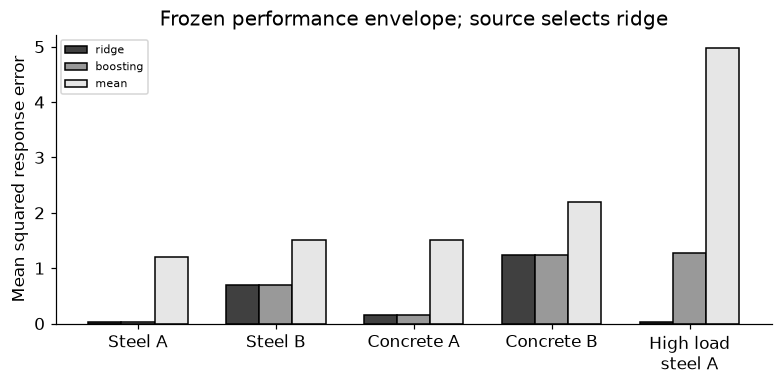

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
def cohort(n,site='A',material='steel',high_load=False):
 load=rng.uniform(70,100,n) if high_load else rng.uniform(10,60,n);age=rng.uniform(0,30,n);X=np.column_stack([load,age]);truth=.2+.04*load+.1*age+(.8 if site=='B' else 0)+(.5*(load/50)**2 if material=='concrete' else 0)+rng.normal(0,.15,n);return X,truth
train_X,train_y=cohort(500);dev_X,dev_y=cohort(150);models={'ridge':make_pipeline(StandardScaler(),Ridge(alpha=1)),'boosting':HistGradientBoostingRegressor(max_iter=100,max_leaf_nodes=7,early_stopping=False,random_state=SEED),'mean':DummyRegressor(strategy='mean')};dev_scores={}
for name,model in models.items():model.fit(train_X,train_y);dev_scores[name]=float(mean_squared_error(dev_y,model.predict(dev_X)))
selected=min(dev_scores,key=dev_scores.get);RESULTS['source_selection']={'train_members':500,'development_members':150,'development_mse':dev_scores,'selected':selected,'refit_on_development':False,'features':['load_kN','age_years']};assert all(np.isfinite(list(dev_scores.values())))
# Challenges are generated only after source selection; all fitted objects stay fixed.
challenges={name:cohort(200,site,material,high) for name,site,material,high in [('steel_A','A','steel',False),('steel_B','B','steel',False),('concrete_A','A','concrete',False),('concrete_B','B','concrete',False),('high_load_steel_A','A','steel',True)]};rows=[]
for challenge,(X,truth) in challenges.items():
 for name,model in models.items():rows.append({'cohort':challenge,'model':name,'members':len(truth),'mse':float(mean_squared_error(truth,model.predict(X))),'mean_residual_prediction_minus_truth':float(np.mean(model.predict(X)-truth)),'selected_before_assessment':name==selected})
assert challenges['high_load_steel_A'][0][:,0].min()>train_X[:,0].max()
RESULTS['challenges']=rows;RESULTS['external_field_evidence']={'available':False,'reason':'all cohorts are independent synthetic draws from author-declared mechanisms'}
fig,ax=plt.subplots(figsize=(7,3.4));positions=np.arange(5)
for j,name in enumerate(models):ax.bar(positions+(j-1)*.24,[r['mse'] for r in rows if r['model']==name],width=.24,color=['.25','.6','.9'][j],edgecolor='black',label=name)
ax.set(xticks=positions,xticklabels=['Steel A','Steel B','Concrete A','Concrete B','High load\nsteel A'],ylabel='Mean squared response error',title=f'Frozen performance envelope; source selects {selected}');ax.legend(fontsize=7);plt.show()


<a id="stress"></a>
## Perturb the observation, preserve the physical target

On the same locked steel-A assessment cohort, add 0,1,5 kN to the recorded load while keeping its generated truth fixed. This sensor-bias intervention differs from changing actual load and regenerating a physical response. Report all fixed procedures; do not choose a new winner on these results. The finite perturbation set measures a specified fragility and does not establish a certified worst-case bound. Cohort error changes may combine bias, support and model limits; synthetic experiments cannot replace an independently collected external site, documented measurement compatibility and outcome follow-up.


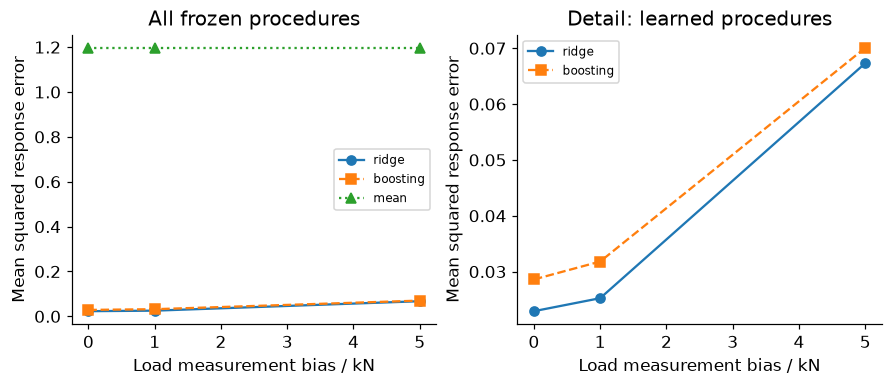

In [3]:
X,truth=challenges['steel_A'];original=X.copy();stress=[]
for bias in [0,1,5]:
 altered=X.copy();altered[:,0]+=bias
 for name,model in models.items():stress.append({'model':name,'load_measurement_bias_kN':bias,'mse':float(mean_squared_error(truth,model.predict(altered)))})
np.testing.assert_array_equal(X,original);assert selected==RESULTS['source_selection']['selected']
RESULTS['sensor_bias_stress']=stress
fig,axes=plt.subplots(1,2,figsize=(8,3.4))
for ax,names,title in zip(axes,[list(models),['ridge','boosting']],['All frozen procedures','Detail: learned procedures']):
 for name,style in zip(models,['-o','--s',':^']):
  if name in names:ax.plot([0,1,5],[r['mse'] for r in stress if r['model']==name],style,label=name)
 ax.set(xlabel='Load measurement bias / kN',ylabel='Mean squared response error',title=title);ax.legend(fontsize=8)
plt.show()


In [4]:
summary={'example_id':'code_071','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['source-only procedure selection', 'separate site material and support shifts', 'frozen sensor-bias stress tests', 'synthetic challenge versus external field evidence'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["source-only procedure selection", "separate site material and support shifts", "frozen sensor-bias stress tests", "synthetic challenge versus external field evidence"], "elapsed_seconds": 0.372, "example_id": "code_071", "hardware": "Darwin arm64 CPU", "results": {"challenges": [{"cohort": "steel_A", "mean_residual_prediction_minus_truth": 0.008544072799142448, "members": 200, "model": "ridge", "mse": 0.02290167199917165, "selected_before_assessment": true}, {"cohort": "steel_A", "mean_residual_prediction_minus_truth": 0.006496420039489771, "members": 200, "model": "boosting", "mse": 0.02858377136041251, "selected_before_assessment": false}, {"cohort": "steel_A", "mean_residual_prediction_minus_truth": 0.07382035350790281, "members": 200, "model": "mean", "mse": 1.1966335492908384, "selected_before_assessment": false}, {"cohort": "steel_B", "mean_residual_prediction_minus_truth": -0.8176647131205822, "members": 200, "model": "ridge", "